# NeuralForecast

`NeuralForecastAdapter` wraps a trained `NeuralForecast` object. Two things about
it differ from the other adapters, and both come from how neuralforecast models
are configured.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MQLoss
from neuralforecast.models import MLP, NHITS

from conformalforecast import (
    ConformalizedQuantileRegression,
    SplitConformal,
    SupportsQuantiles,
    UnsupportedCapability,
)
from conformalforecast import (
    panel as P,
)
from conformalforecast.adapters import NeuralForecastAdapter
from conformalforecast.diagnostics import coverage_by_series, evaluate

HORIZON, ALPHA = 24, 0.1
N_HOLDOUT = 3

df = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
matrix, index = P.long_to_panel(df["y"].to_numpy(), df["unique_id"].to_numpy(), df["ds"].to_numpy())
print("panel", matrix.shape)

# Hold the tail out before anything is fitted, so the coverage measured at the
# end of this page is measured on data no part of the pipeline has seen.
train_df = df[df["ds"] <= df["ds"].max() - pd.Timedelta(hours=N_HOLDOUT * HORIZON)].reset_index(
    drop=True
)
print("training through", train_df["ds"].max(), f"({N_HOLDOUT * HORIZON} hours held out)")

panel (8, 672)
training through 2015-01-25 23:00:00 (72 hours held out)


## The horizon comes from the model

`NeuralForecastAdapter` takes **no `horizon` argument**. A neuralforecast model
is built with its own `h`, and the adapter reads it. Copy the constructor call
from the [StatsForecast page](statsforecast), add `horizon=`, and you get a
`TypeError`. If the `NeuralForecast` holds several models they must all agree
on `h`.

In [ ]:
nf = NeuralForecast(
    models=[
        NHITS(
            h=HORIZON,
            input_size=3 * HORIZON,
            max_steps=100,
            scaler_type="standard",
            enable_progress_bar=False,
            enable_model_summary=False,
            logger=False,
            accelerator="cpu",
            random_seed=0,
        )
    ],
    freq="h",
)
nf.fit(train_df)

forecaster = NeuralForecastAdapter(
    nf=nf,
    train_df=train_df,
    freq="h",
    model_name="NHITS",  # note: no horizon=
)
print("horizon read from the model:", forecaster.horizon)

horizon read from the model: 24


::: {.callout-note}
## `scaler_type` matters as much as it does for a boosted model

These eight series span three orders of magnitude. `scaler_type="standard"`
normalises per series inside the model; without it, the network fits the
largest series and ignores the rest — the same failure the
[MLForecast page](mlforecast) documents for unscaled trees.
:::

In [ ]:
split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=20)
print("effective windows:", split.n_calibration_samples_)

prediction = split.predict(matrix)
print("interval", prediction.interval.shape)

effective windows: [20 20 20 20 20 20 20 20]
interval (8, 1, 24, 2)


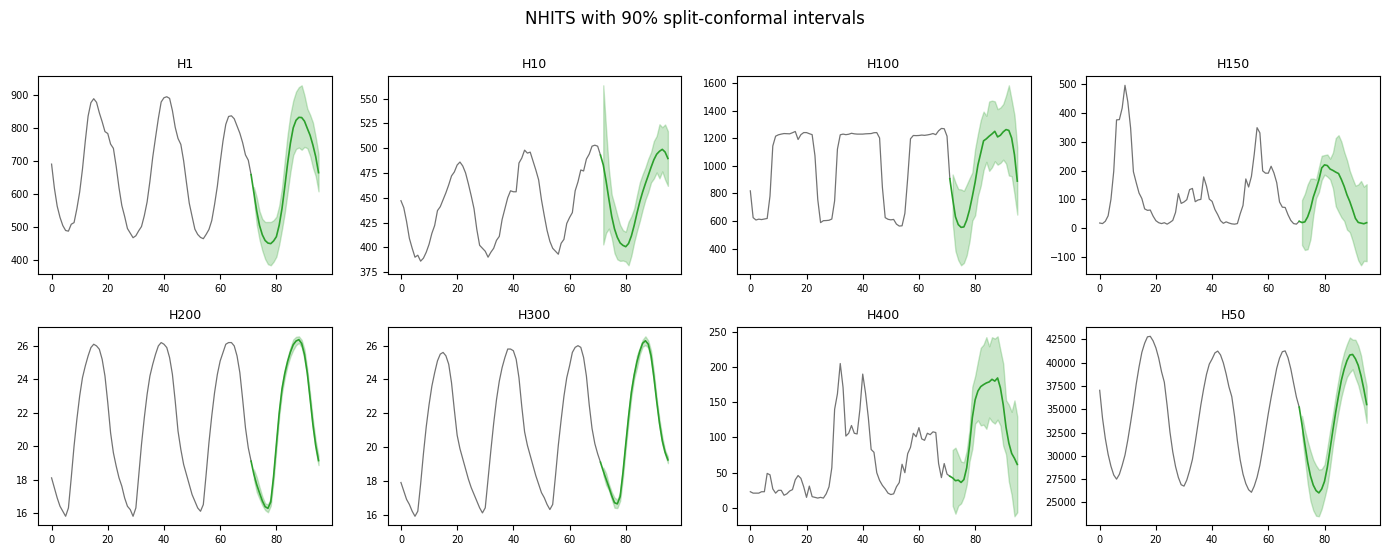

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
context = 72

for s, ax in enumerate(axes.ravel()):
    history = matrix[s]
    observed = history[~np.isnan(history)][-context:]
    past = np.arange(len(observed))
    future = np.arange(len(observed), len(observed) + HORIZON)
    join = np.r_[past[-1], future]

    ax.plot(past, observed, color="0.45", lw=0.9)
    ax.plot(join, np.r_[observed[-1], prediction.point[s, 0]], color="C2", lw=1.2)
    ax.fill_between(
        future,
        prediction.interval[s, 0, :, 0],
        prediction.interval[s, 0, :, 1],
        color="C2",
        alpha=0.25,
    )
    ax.set_title(index.series_ids[s], fontsize=9)
    ax.tick_params(labelsize=7)

fig.suptitle("NHITS with 90% split-conformal intervals", y=1.0)
fig.tight_layout()

## Quantile capability depends on the loss

This is the package's clearest example of a capability that is a property of the
*instance*, not the class. A neuralforecast model trained with a point loss
cannot produce quantiles; the same class trained with `MQLoss` can. So
`NeuralForecastAdapter` overrides `supports()` to inspect the loss.

In [ ]:
print("NHITS with the default point loss:")
print("  SupportsQuantiles ->", forecaster.supports(SupportsQuantiles))
# The gate fires where the forecaster is bound, not at construction.
try:
    ConformalizedQuantileRegression(alpha=ALPHA).calibrate_cv(forecaster, n_windows=20)
except UnsupportedCapability as error:
    print(" ", error)

NHITS with the default point loss:
  SupportsQuantiles -> False
  ConformalizedQuantileRegression requires an adapter implementing SupportsQuantiles. Got NeuralForecastAdapter.


Train the same architecture with a quantile loss and the answer changes. `MQLoss`
needs the quantile levels it will be asked for — `alpha=0.1` means the pair
`(0.05, 0.95)`.

In [ ]:
nf_quantile = NeuralForecast(
    models=[
        MLP(
            h=HORIZON,
            input_size=3 * HORIZON,
            max_steps=100,
            loss=MQLoss(quantiles=[0.05, 0.95]),
            scaler_type="standard",
            enable_progress_bar=False,
            enable_model_summary=False,
            logger=False,
            accelerator="cpu",
            random_seed=0,
        )
    ],
    freq="h",
)
nf_quantile.fit(train_df)

quantile_forecaster = NeuralForecastAdapter(
    nf=nf_quantile, train_df=train_df, freq="h", model_name="MLP"
)
print("MLP with MQLoss:")
print("  SupportsQuantiles ->", quantile_forecaster.supports(SupportsQuantiles))

cqr = ConformalizedQuantileRegression(alpha=ALPHA)
cqr_fitted = cqr.calibrate_cv(quantile_forecaster, n_windows=20)
print("  CQR calibrated, levels", cqr.quantile_levels)

MLP with MQLoss:
  SupportsQuantiles -> True


  CQR calibrated, levels [0.05 0.95]


The check is the first thing `calibrate_cv` does, so the failure above cost
nothing — no cross-validation ran. That is the rule the package holds to
everywhere: capability errors surface where the forecaster is bound, never
inside `predict`.

## Measured coverage

In [ ]:
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = matrix.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(matrix[:, :end])
    truths.append(matrix[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

reports = {
    name: evaluate(candidate, histories, truths)
    for name, candidate in [("NHITS + Split", split), ("MLP(MQLoss) + CQR", cqr_fitted)]
}
for name, report in reports.items():
    print(
        f"{name:22s} coverage {report.marginal_coverage:6.1%}   "
        f"width {report.mean_interval_width:9.1f}   "
        f"Winkler {report.mean_winkler_score:9.1f}"
    )

split_report = reports["NHITS + Split"]
print("\nNHITS + Split, coverage per series:")
per_series = coverage_by_series(split_report.intervals, split_report.truths)
for name, value in zip(index.series_ids, per_series, strict=True):
    print(f"  {name:6s} {value:6.1%}")

NHITS + Split          coverage  85.6%   width     609.6   Winkler     900.0
MLP(MQLoss) + CQR      coverage  86.3%   width     577.1   Winkler     772.9

NHITS + Split, coverage per series:
  H1      87.5%
  H10     98.6%
  H100    93.1%
  H150    77.8%
  H200    95.8%
  H300    95.8%
  H400    47.2%
  H50     88.9%


Both land under the 90% target, at 85.6% and 86.3%, on three days the models were
not trained through. Two causes are mixed together: the models are deliberately
undertrained, for the reason in the note below, and 20 calibration windows is a
thin sample from which to take a 90% quantile for each of 24 horizon steps.

The `MQLoss` model with CQR beats the point model with split conformal on all
three numbers — better coverage, narrower, lower Winkler. That is the shape CQR
has when a model's own quantiles carry real information about where its errors
fall, and it is worth contrasting with the [StatsForecast page](statsforecast),
where CQR loses for exactly the opposite reason.

::: {.callout-note}
## `max_steps=100` is a documentation setting

Both models here train for 100 steps so this page builds in seconds. That is far
short of convergence, and the intervals are correspondingly wide — conformal
prediction is honest about an undertrained model rather than hiding it. Raise
`max_steps` for anything real; the calibration code is unchanged.
:::

## Next

- [StatsForecast](statsforecast) — per-series statistical models.
- [MLForecast](mlforecast) — a global gradient-boosted model.
- [CQR](../methods/cqr) — what the `MQLoss` path above feeds.
- [Adapters](index) — the capability matrix in full.